# 2. Plot and save figures

This notebook is the single plotting pipeline. It reads only the tables,
TIFFs, and compact plot-data bundles produced by notebook 01. No beam–wire
interaction or free-space propagation is repeated here.

The sections follow the same order as notebook 01. Figures are written directly
to their established output directories; a final manifest indexes them without
making duplicate copies. The clean SAXS and PCI figures include the additional
target-plane FWHM = 6 µm case generated by notebook 01.

The selected calculation and all generated figures live under
`outputs/sigmaL_<left>nm_sigmaR_<right>nm/`. Use the same
`WIRE_SIGMA_LEFT_NM` and `WIRE_SIGMA_RIGHT_NM` values as notebook 01.


## Load plotting setup


In [1]:
from pathlib import Path
import json
import os
import pickle
import sys

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
from PIL import Image
from scipy import interpolate

START_DIR = Path.cwd()
if (START_DIR / "PCI.py").exists():
    SAXS_DIR = START_DIR
elif (START_DIR / "SAXS_asymmetry" / "PCI.py").exists():
    SAXS_DIR = START_DIR / "SAXS_asymmetry"
else:
    raise RuntimeError("Run from the repository root or SAXS_asymmetry/ directory.")
os.chdir(SAXS_DIR)
if str(SAXS_DIR) not in sys.path:
    sys.path.insert(0, str(SAXS_DIR))

import PCI
import rossendorfer_farbenliste as rofl

INPUT_DIR = SAXS_DIR / "inputs"
OUTPUT_ROOT = SAXS_DIR / "outputs"

# Use the same sigma selection as notebook 01. Each selection has its own
# complete calculation and plotting tree below outputs/.
WIRE_SIGMA_LEFT_NM = 4.0  # Fixed left wire sigma in nm
WIRE_SIGMA_RIGHT_NM = 4.0  # Fixed right wire sigma in nm


def sigma_value_tag(value_nm):
    return f"{value_nm:g}".replace(".", "p")

SIGMA_TAG = (
    f"sigmaL_{sigma_value_tag(WIRE_SIGMA_LEFT_NM)}nm_"
    f"sigmaR_{sigma_value_tag(WIRE_SIGMA_RIGHT_NM)}nm"
)
OUTPUT_DIR = OUTPUT_ROOT / SIGMA_TAG
PLOT_DATA_DIR = OUTPUT_DIR / "combined_plot_data"
CLEAN_PCI_DIR = OUTPUT_DIR / "clean_pci"
REALISTIC_DIR = OUTPUT_DIR / "realistic_profile"
REALISTIC_TABLE_DIR = REALISTIC_DIR / "tables"
REALISTIC_FIGURE_DIR = REALISTIC_DIR / "figures"
SAXS_PICKLE_DIR = INPUT_DIR / "experimental" / "SAXSData"
ERIK_DIR = INPUT_DIR / "experimental" / "Erik"
LINGEN_REFERENCE_PATH = INPUT_DIR / "reference" / "DivSAXS_asymmetry_Mark1300_6um_lg.dat"
TRANSMISSION_SCAN_PATH = INPUT_DIR / "experimental" / "MotoPosition_Zyla_r0484.dat"

N_GRID = 4096
PIXEL_SIZE = 8 * PCI.nm
Z_SAXS_DETECTOR = 1.31 * PCI.m
Q_MAX = np.pi / PIXEL_SIZE
Q_AXIS = np.linspace(-Q_MAX, Q_MAX, N_GRID)
Q_STEP = 2 * np.pi / (N_GRID * PIXEL_SIZE)
Q_MIN = 0.10
Q_MASK_SHIFT_NM_INV = 0.005
Q_COMPARE_MAX = 0.30 # Maximum Q value for comparison
MOTOR_POSITION_UNCERTAINTY_UM = 1.0
EXPERIMENTAL_RUNS = (528, 534, 546)

# Shared imshow extents, so every figure uses the same axes conventions.
SAMPLE_AXIS_UM = (np.arange(N_GRID) - N_GRID // 2) * PIXEL_SIZE / PCI.um
SAMPLE_EXTENT_UM = [SAMPLE_AXIS_UM[0], SAMPLE_AXIS_UM[-1]] * 2
Q_EXTENT = [-Q_STEP * N_GRID / 2, Q_STEP * N_GRID / 2] * 2

plt.rcParams.update({"figure.facecolor": "white", "axes.grid": False})

def require(path):
    path = Path(path)
    if not path.exists():
        raise RuntimeError(f"Missing {path}; run 01_calculate_and_save_data.ipynb first.")
    return path

def load_tiff(path):
    with Image.open(require(path)) as image:
        return np.asarray(image, dtype=np.float32).copy()

def save_figure(fig, path, *, dpi=200):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    return path

def offset_tag(offset_um, decimals=1):
    return f"{offset_um:+.{decimals}f}".replace("+", "p").replace("-", "m").replace(".", "p")

def load_run_halves(run):
    """Return the measured (positive q, left, right) half-profiles for one run."""
    path = SAXS_PICKLE_DIR / f"profiles_cleaned_p3129_r{run:04d}.pickle"
    with require(path).open("rb") as stream:
        q_positive, left, right = pickle.load(stream)[:3]
    return (
        np.asarray(q_positive, dtype=float),
        np.nan_to_num(np.asarray(left, dtype=float), nan=0.0),
        np.nan_to_num(np.asarray(right, dtype=float), nan=0.0),
    )

def load_pointing_profiles():
    """Mirror each measured half-profile into a full signed-q pointing lineout."""
    scales = {528: 50e3, 534: 80e3, 546: 80e3}
    profiles = {}
    for run, scale in scales.items():
        q_positive, left, right = load_run_halves(run)
        q = np.concatenate((np.flip(-q_positive)[:-1], q_positive))
        lineout = np.concatenate((np.flip(left)[:-1], right))
        profiles[run] = (q, lineout / lineout.max() / scale)
    return profiles

def load_realistic_experimental_profile(run):
    """Sorted signed-q profile normalized over the Q_MIN..Q_COMPARE_MAX band."""
    q_positive, left, right = load_run_halves(run)
    keep = np.isfinite(q_positive) & (q_positive >= 0)
    q_positive, left, right = q_positive[keep], left[keep], right[keep]
    order = np.argsort(q_positive)
    q_positive, left, right = q_positive[order], left[order], right[order]
    q_signed = np.concatenate((-q_positive[:0:-1], q_positive))
    intensity = np.concatenate((left[:0:-1], right))
    scale_mask = (np.abs(q_signed) >= Q_MIN) & (np.abs(q_signed) <= Q_COMPARE_MAX)
    outer = q_positive >= Q_MIN
    return {
        "q": q_signed,
        "normalized": intensity / np.max(intensity[scale_mask]),
        "left_fraction": left[outer].sum() / (left[outer].sum() + right[outer].sum()),
    }

def load_erik_reference():
    """Externally supplied collimated-beam left/right scan and the motor scan."""
    ratio = np.load(require(ERIK_DIR / "left_div_right.npy")).astype(float)
    total = np.load(require(ERIK_DIR / "left_plus_right.npy")).astype(float)
    right = total / (1 + ratio)
    return {
        "offsets_um": np.load(require(ERIK_DIR / "pos_grid.npy")).astype(float) / 1e3,
        "left": ratio * right,
        "right": right,
        "total": total,
        "left_fraction": ratio / (1 + ratio),
        "motor_offsets_um": np.load(require(ERIK_DIR / "motor_positions_um.npy")),
        "motor_left_fraction": np.load(require(ERIK_DIR / "left_div_left_right_exp.npy")),
    }

def load_transmission_scan():
    """XGM-normalized r0484 transmission, re-zeroed on its minimum."""
    data = np.loadtxt(require(TRANSMISSION_SCAN_PATH))
    if data.shape[0] != 3 and data.shape[1] == 3:
        data = data.T
    minimum = int(np.nanargmin(data[2]))
    return (data[0] - data[0, minimum]) * 1e3, data[2] / np.nanmax(data[2])

manifest_path = require(PLOT_DATA_DIR / "calculation_manifest.json")
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
if manifest.get("sigma_tag") != SIGMA_TAG:
    raise RuntimeError(
        f"Sigma selection {SIGMA_TAG!r} does not match manifest "
        f"{manifest.get('sigma_tag')!r}. Rerun notebook 01 with the same settings."
    )

# Loaded once here so every section below shares the same experimental references.
pointing_experimental = load_pointing_profiles()
erik = load_erik_reference()
transmission_position_um, transmission = load_transmission_scan()

print(f"Wire blur: left={WIRE_SIGMA_LEFT_NM:g} nm, right={WIRE_SIGMA_RIGHT_NM:g} nm")
print(f"Plotting artifacts from: {OUTPUT_DIR.resolve()}")


PCI successfully compiled. You can get more help by typing 'PCI.help()'


  This program comes with ABSOLUTELY NO WARRANTY; for details type `show w'.
  This is free software, and you are welcome to redistribute it
  under certain conditions; type `show c' for details.
Wire blur: left=4 nm, right=4 nm
Plotting artifacts from: C:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\sigmaL_4nm_sigmaR_4nm


## 1. Clean SAXS figures


### Quick sigma and Mark1300 check

After running the setup cell, run this cell by itself for a lightweight check. It reads only the two saved Mark1300 tables; it does not load detector TIFFs or repeat propagation. The first panel shows the normalized Gaussian kernels for the configured boundary sigmas, and the other panels compare the 7.11 µm and 6 µm divergent Mark1300 results.


Sigma check passed: left=4 nm, right=4 nm
Saved: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\sigmaL_4nm_sigmaR_4nm\saxs\figures\quick_sigma_Mark1300_7p11um_vs_6um.png


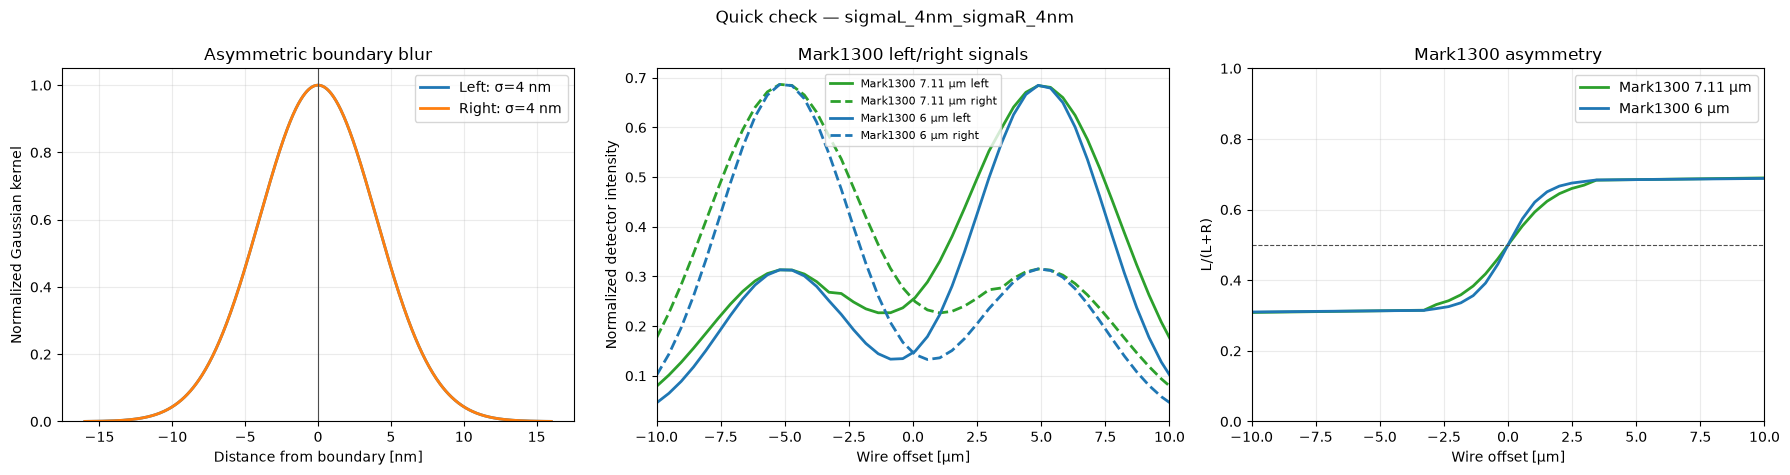

In [ ]:
# Quick check: no TIFF loading and no propagation.
manifest_sigmas = (
    float(manifest.get("wire_sigma_left_nm", np.nan)),  # Left wire sigma from manifest
    float(manifest.get("wire_sigma_right_nm", np.nan)),  # Right wire sigma from manifest
)
configured_sigmas = (WIRE_SIGMA_LEFT_NM, WIRE_SIGMA_RIGHT_NM)
if not np.allclose(manifest_sigmas, configured_sigmas):
    raise RuntimeError(
        f"Configured sigmas {configured_sigmas} do not match manifest {manifest_sigmas}. "
        "Rerun notebook 01."
    )

quick_table_dir = OUTPUT_DIR / "saxs" / "tables"
quick_figure_dir = OUTPUT_DIR / "saxs" / "figures"
quick_mark1300_cases = {
    "Mark1300 7.11 µm": quick_table_dir / "DivSAXS_asymmetry_Mark1300_7p11um.dat",
    "Mark1300 6 µm": quick_table_dir / "DivSAXS_asymmetry_Mark1300_6um.dat",
}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
sigma_axis_nm = np.linspace(
    -4 * max(configured_sigmas), 4 * max(configured_sigmas), 801
)
for side, sigma_nm, color in (
    ("Left", WIRE_SIGMA_LEFT_NM, "tab:blue"),
    ("Right", WIRE_SIGMA_RIGHT_NM, "tab:orange"),
):
    kernel = np.exp(-0.5 * (sigma_axis_nm / sigma_nm) ** 2)
    axes[0].plot(sigma_axis_nm, kernel, lw=2, color=color,
                 label=f"{side}: σ={sigma_nm:g} nm")
axes[0].axvline(0, color="0.3", lw=0.8)
axes[0].set(
    xlabel="Distance from boundary [nm]",
    ylabel="Normalized Gaussian kernel",
    title="Asymmetric boundary blur", ylim=(0, 1.05),
)
axes[0].grid(alpha=0.25); axes[0].legend()

for (label, table_path), color in zip(
    quick_mark1300_cases.items(), ("tab:green", "tab:blue")
):
    table = np.loadtxt(require(table_path))
    offsets_um = table[:, 0] / 1e3
    left, right = table[:, 1], table[:, 2]
    scale = np.nanmax(left + right)
    axes[1].plot(offsets_um, left / scale, color=color, lw=2,
                 label=f"{label} left")
    axes[1].plot(offsets_um, right / scale, color=color, lw=2, ls="--",
                 label=f"{label} right")
    axes[2].plot(offsets_um, left / (left + right), color=color, lw=2,
                 label=label)
axes[1].set(
    xlabel="Wire offset [µm]", ylabel="Normalized detector intensity",
    title="Mark1300 left/right signals", xlim=(-10, 10),
)
axes[1].grid(alpha=0.25); axes[1].legend(fontsize=8)
axes[2].axhline(0.5, color="0.3", lw=0.8, ls="--")
axes[2].set(
    xlabel="Wire offset [µm]", ylabel="L/(L+R)",
    title="Mark1300 asymmetry", xlim=(-10, 10), ylim=(0, 1),
)
axes[2].grid(alpha=0.25); axes[2].legend()
fig.suptitle(f"Quick check — {SIGMA_TAG}")
fig.tight_layout()
quick_check_path = save_figure(
    fig, quick_figure_dir / "quick_sigma_Mark1300_7p11um_vs_6um.png"
)
print(f"Sigma check passed: left={manifest_sigmas[0]:g} nm, right={manifest_sigmas[1]:g} nm")
print(f"Saved: {quick_check_path}")
plt.show()


In [3]:
SAXS_OUTPUT_DIR = OUTPUT_DIR / "saxs"
SAXS_TABLE_DIR = SAXS_OUTPUT_DIR / "tables"
SAXS_FIGURE_DIR = SAXS_OUTPUT_DIR / "figures"
SAXS_TIFF_ROOT = SAXS_OUTPUT_DIR / "detector_tiffs" / f"Data_{PIXEL_SIZE:g}nm"

clean_cases = {
    "mark1300_7p11um": {
        "label": "Mark1300 divergent, 7.11 µm FWHM at target",
        "table": SAXS_TABLE_DIR / "DivSAXS_asymmetry_Mark1300_7p11um.dat",
    },
    "collimated_7p11um": {
        "label": "Collimated (large-root), 7.11 µm FWHM at target",
        "table": SAXS_TABLE_DIR / "CollimatedSAXS_asymmetry_Mark1300_7p11um.dat",
    },
    "mark1300_6um": {
        "label": "Mark1300 divergent, 6 µm FWHM at target",
        "table": SAXS_TABLE_DIR / "DivSAXS_asymmetry_Mark1300_6um.dat",
    },
    "collimated_6um": {
        "label": "Collimated (large-root), 6 µm FWHM at target",
        "table": SAXS_TABLE_DIR / "CollimatedSAXS_asymmetry_Mark1300_6um.dat",
    },
}
clean_profiles = np.load(require(PLOT_DATA_DIR / "clean_saxs_profiles.npz"))
pointing_q = clean_profiles["q_reference"]

for case_name, case in clean_cases.items():
    table = np.loadtxt(require(case["table"]))
    offsets_um = table[:, 0] / 1e3
    fractions = table[:, 1] / (table[:, 1] + table[:, 2])
    lineouts = clean_profiles[f"{case_name}_lineouts"]
    results_dir = SAXS_FIGURE_DIR / f"Results_{PIXEL_SIZE:g}nm" / case_name
    data_dir = SAXS_TIFF_ROOT / case_name
    for index, (offset_um, fraction, lineout) in enumerate(
        zip(offsets_um, fractions, lineouts), start=1
    ):
        intensity = load_tiff(data_dir / f"SAXS_Offset{offset_um:.2f}um.tif")
        fig, axes = plt.subplots(2, 1, figsize=(10, 8))
        image = axes[0].imshow(
            intensity, origin="lower", extent=Q_EXTENT, aspect="auto",
            cmap="inferno", norm=LogNorm(vmin=1e-11, vmax=5e-8),
        )
        axes[0].set(
            xlabel=r"$Q_x$ [nm$^{-1}$]", ylabel=r"$Q_y$ [nm$^{-1}$]",
            title=f"{case['label']}, offset {offset_um:.1f} µm, L/(L+R)={fraction:.4f}",
            xlim=(-0.4, 0.4), ylim=(-0.005, 0.005),
        )
        fig.colorbar(image, ax=axes[0], label="Intensity")
        axes[1].semilogy(pointing_q, lineout, "--", label=f"Simulated {offset_um:.1f} µm")
        for run, (q_values, experimental) in pointing_experimental.items():
            axes[1].semilogy(q_values, experimental, "o-", markersize=3, label=f"Exp. Run {run}")
        axes[1].set(
            xlabel=r"$Q_x$ [nm$^{-1}$]", ylabel="Normalized intensity",
            xlim=(-0.4, 0.4), ylim=(1e-8, 5e-4),
        )
        axes[1].grid(alpha=0.25)
        axes[1].legend()
        fig.tight_layout()
        output_path = results_dir / (
            f"SAXS_offset{offset_um:.1f}um_{case_name}_"
            f"Pix{PIXEL_SIZE:g}nm_D{Z_SAXS_DETECTOR / PCI.m:.2f}m.png"
        )
        save_figure(fig, output_path)
        plt.close(fig)
        del intensity
    print(f"Clean SAXS figures: {case_name} ({len(offsets_um)})")


Clean SAXS figures: mark1300_7p11um (43)
Clean SAXS figures: collimated_7p11um (43)
Clean SAXS figures: mark1300_6um (43)
Clean SAXS figures: collimated_6um (43)


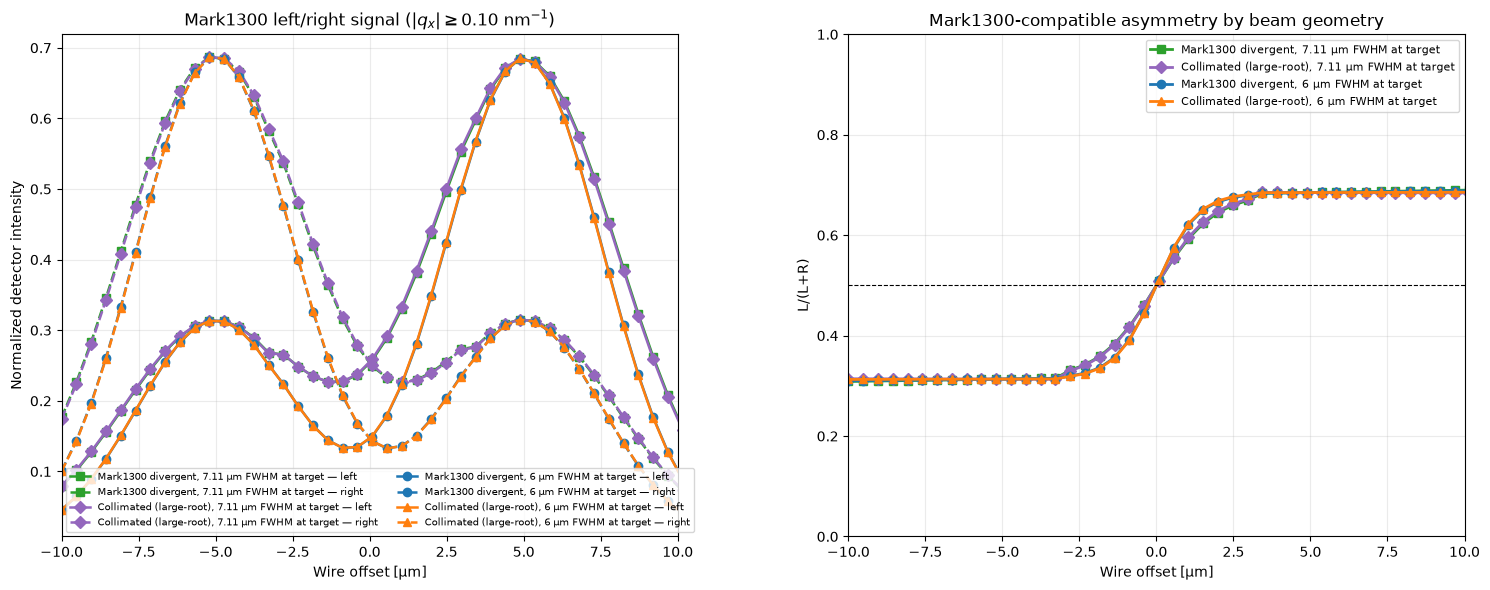

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
styles = {
    "mark1300_7p11um": dict(color="tab:green", marker="s"),
    "collimated_7p11um": dict(color="tab:purple", marker="D"),
    "mark1300_6um": dict(color="tab:blue", marker="o"),
    "collimated_6um": dict(color="tab:orange", marker="^"),
}
for case_name, case in clean_cases.items():
    table = np.loadtxt(case["table"])
    offsets_um, left, right = table[:, 0] / 1e3, table[:, 1], table[:, 2]
    scale = np.nanmax(left + right)
    axes[0].plot(offsets_um, left / scale, "-", lw=1.8,
                 label=f"{case['label']} — left", **styles[case_name])
    axes[0].plot(offsets_um, right / scale, "--", lw=1.8,
                 label=f"{case['label']} — right", **styles[case_name])
    axes[1].plot(offsets_um, left / (left + right), "-", lw=2,
                 label=case["label"], **styles[case_name])
axes[0].set(
    xlabel="Wire offset [µm]", ylabel="Normalized detector intensity",
    title=r"Mark1300 left/right signal ($|q_x| \geq 0.10$ nm$^{-1}$)", xlim=(-10, 10),
)
axes[0].grid(alpha=0.25); axes[0].legend(fontsize=7, ncol=2)
axes[1].axhline(0.5, color="k", lw=0.8, ls="--")
axes[1].set(
    xlabel="Wire offset [µm]", ylabel="L/(L+R)",
    title="Mark1300-compatible asymmetry by beam geometry", xlim=(-10, 10), ylim=(0, 1),
)
axes[1].grid(alpha=0.25); axes[1].legend(fontsize=8)
fig.tight_layout()
save_figure(fig, SAXS_FIGURE_DIR / "SAXS_Mark1300_collimated_6um_7p11um.png")
plt.show()


## 2. SAXS asymmetry-method figures and gallery 1. SAXS Asymmetry postprocess: no shift, no sigma


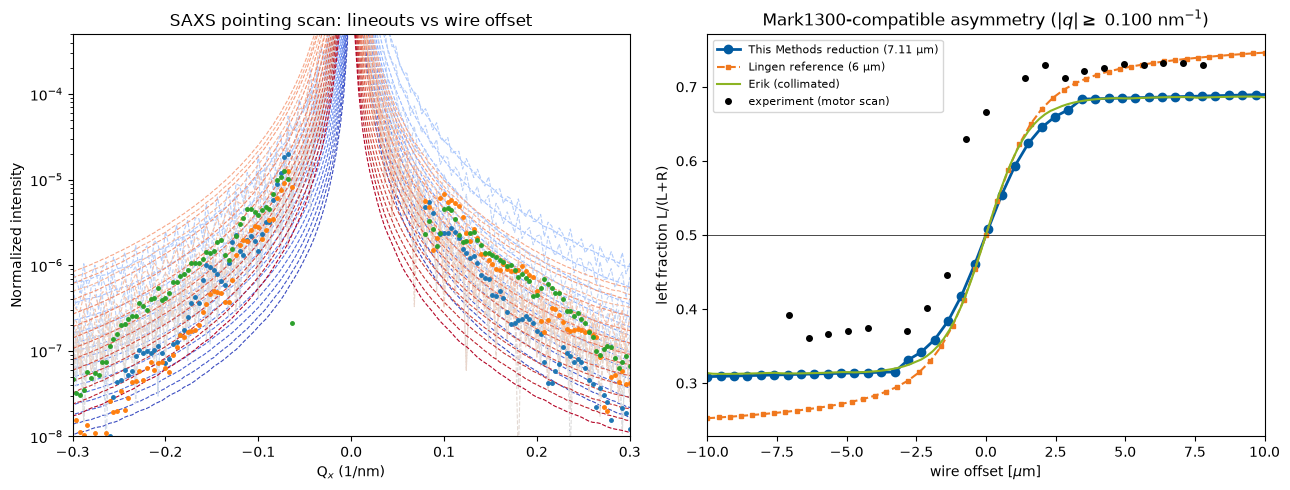

In [5]:
METHODS_DIR = OUTPUT_DIR / "methods"
METHODS_TABLE_DIR = METHODS_DIR / "tables"
METHODS_FIGURE_DIR = METHODS_DIR / "figures"
METHODS_MOVIE_DIR = METHODS_DIR / "movie" / "7p11um"
METHODS_FRAME_DIR = METHODS_MOVIE_DIR / "frames"
METHODS_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
METHODS_FRAME_DIR.mkdir(parents=True, exist_ok=True)

methods_profiles = np.load(require(PLOT_DATA_DIR / "methods_pointing_profiles.npz"))
methods_table = np.loadtxt(require(METHODS_TABLE_DIR / "DivSAXS_asymmetry_Methods_7p11um.dat"))
methods_offsets_um = methods_table[:, 0] / 1e3
methods_fraction = methods_table[:, 1] / (methods_table[:, 1] + methods_table[:, 2])
lingen_table = np.loadtxt(require(LINGEN_REFERENCE_PATH))
lingen_offsets_um = lingen_table[:, 0] / 1e3
lingen_fraction = lingen_table[:, 1] / (lingen_table[:, 1] + lingen_table[:, 2])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cmap = plt.cm.coolwarm
for offset_um, lineout in zip(methods_profiles["offsets_um"], methods_profiles["lineouts"]):
    axes[0].semilogy(
        methods_profiles["q"], lineout, "--",
        color=cmap((offset_um - methods_offsets_um.min()) / np.ptp(methods_offsets_um)),
        lw=0.8, label=f"{offset_um:+.1f} um",
    )
for run, (q_values, experimental) in pointing_experimental.items():
    axes[0].semilogy(q_values, experimental, "o", ms=2.5, label=f"Exp. Run {run}")
axes[0].set(
    xlim=(-0.3, 0.3), ylim=(1e-8, 5e-4), xlabel=r"Q$_x$ (1/nm)",
    ylabel="Normalized intensity", title="SAXS pointing scan: lineouts vs wire offset",
)
#axes[0].grid(alpha=0.25); axes[0].legend(fontsize=6, ncol=2, title="wire offset / data")
axes[1].plot(methods_offsets_um, methods_fraction, "o-", color=rofl.b(), lw=2,
             label="This Methods reduction (7.11 µm)")
axes[1].plot(lingen_offsets_um, lingen_fraction, "s--", ms=3, color=rofl.o(),
             label="Lingen reference (6 µm)")
axes[1].plot(erik["offsets_um"], erik["left_fraction"], "-", color=rofl.g(), label="Erik (collimated)")
axes[1].plot(erik["motor_offsets_um"], erik["motor_left_fraction"], "ko", ms=4, label="experiment (motor scan)")
axes[1].axhline(0.5, color="k", lw=0.5)
axes[1].set(
    xlabel=r"wire offset [$\mu$m]", ylabel="left fraction L/(L+R)", xlim=(-10, 10),
    title=rf"Mark1300-compatible asymmetry ($|q| \geq$ {Q_MIN:.3f} nm$^{{-1}}$)",
)
axes[1].legend(fontsize=8, loc="upper left")
fig.tight_layout()
save_figure(fig, METHODS_FIGURE_DIR / "01_offset_scan.png")
plt.show()


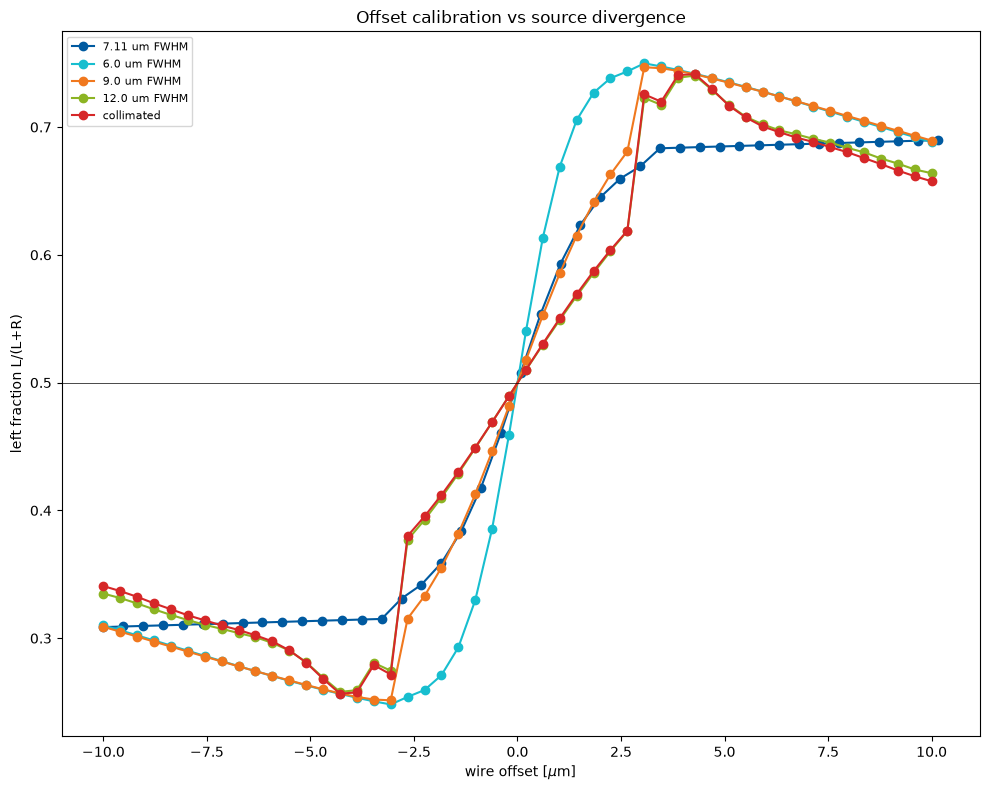

In [6]:
divergence = np.genfromtxt(
    require(METHODS_TABLE_DIR / "DivSAXS_divergence_vs_offset_Methods.dat"),
    delimiter="\t", names=True, dtype=None, encoding="utf-8",
)
fig, ax = plt.subplots(figsize=(10, 8))
case_order = list(dict.fromkeys(divergence["case"].tolist())) # create a list of unique case names in the order they first appear
required_fields = {"case", "offset_um", "mark1300_frac"}
missing_fields = required_fields.difference(divergence.dtype.names)
if missing_fields:
    raise ValueError(f"Divergence table is missing columns: {sorted(missing_fields)}")
case_colors = {
    "7.11 um FWHM": rofl.b(),
    "6.0 um FWHM": "tab:cyan",
    "9.0 um FWHM": rofl.o(),
    "12.0 um FWHM": rofl.g(),
    "collimated": "tab:red",
}
for case_name in case_order:
    rows = divergence[divergence["case"] == case_name]
    ax.plot(
        rows["offset_um"], rows["mark1300_frac"], "o-",
        color=case_colors.get(case_name, "0.35"), label=case_name,
    )
ax.axhline(0.5, color="k", lw=0.5)
ax.set(
    xlabel=r"wire offset [$\mu$m]", ylabel="left fraction L/(L+R)",
    title="Offset calibration vs source divergence",
)
ax.legend(fontsize=8)
fig.tight_layout()
save_figure(fig, METHODS_FIGURE_DIR / "05_divergence_scan.png")
plt.show()


In [7]:
# Use every offset generated by notebook 01 on its regular 0.48 um grid.
gallery_offsets_um = np.asarray(methods_profiles["offsets_um"], dtype=float)
gif_frames = []
pci_half_width_um = N_GRID * PIXEL_SIZE / (2 * PCI.um)
q_half_width = float(np.abs(Q_AXIS).max())
for frame_index, offset_um in enumerate(gallery_offsets_um):
    pci = load_tiff(METHODS_MOVIE_DIR / f"DivPCI_AfterSample_Offset{offset_um:.2f}um.tif")
    saxs = load_tiff(METHODS_MOVIE_DIR / f"DivSAXS_Offset{offset_um:.2f}um.tif")
    pci_max, saxs_max = float(np.nanmax(pci)), float(np.nanmax(saxs))
    step = max(1, N_GRID // 1024)
    pci_display, saxs_display = pci[::step, ::step], saxs[::step, ::step]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
    axes[0].imshow(
        pci_display, origin="lower", cmap=rofl.cmap(),
        extent=[-pci_half_width_um, pci_half_width_um] * 2, vmin=0, vmax=pci_max,
    )
    axes[0].set(
        xlabel="Sample-plane x [µm]", ylabel="Sample-plane y [µm]",
        title=r"PCI immediately after sample: $|E_{\rm exit}|^2$",
    )
    axes[1].imshow(
        saxs_display, origin="lower", cmap=rofl.cmap(),
        extent=[-q_half_width, q_half_width] * 2,
        norm=LogNorm(vmin=max(saxs_max * 1e-9, np.finfo(float).tiny), vmax=saxs_max),
        aspect="auto",
    )
    axes[1].set(
        xlabel=r"Q$_x$ [1/nm]", ylabel=r"Q$_y$ [1/nm]",
        title="SAXS at detector (log scale)", ylim=(-0.08, 0.08),
    )
    fig.suptitle(f"Wire offset {offset_um:+.1f} µm — PCI exit and SAXS detector")
    fig.tight_layout()
    frame_path = METHODS_FRAME_DIR / f"frame{frame_index:02d}_offset{offset_um:+.1f}um.png"
    save_figure(fig, frame_path, dpi=120)
    plt.close(fig)
    with Image.open(frame_path) as frame:
        gif_frames.append(frame.convert("RGB").copy())
    del pci, saxs
gif_path = METHODS_MOVIE_DIR / "PCI_after_sample_SAXS_detector_offset_scan.gif"
gif_frames[0].save(
    gif_path, save_all=True, append_images=gif_frames[1:], duration=350, loop=0
)
print(f"Methods gallery: {gif_path}")


Methods gallery: c:\Users\feng48\Downloads\PCI_Codebase\PCI_Codebase\SAXS_asymmetry\outputs\sigmaL_4nm_sigmaR_4nm\methods\movie\7p11um\PCI_after_sample_SAXS_detector_offset_scan.gif


## 3. Clean PCI figures

The center-row thickness panel compares symmetric wire-edge blur with
sigmaL = sigmaR = 0, 4, and 8 nm. Each curve starts from the same unblurred
5 um-radius wire chord and uses notebook 01's Gaussian settings. Only these
one-dimensional comparison profiles are calculated here; the image panels
use the saved fields for the selected sigma model.


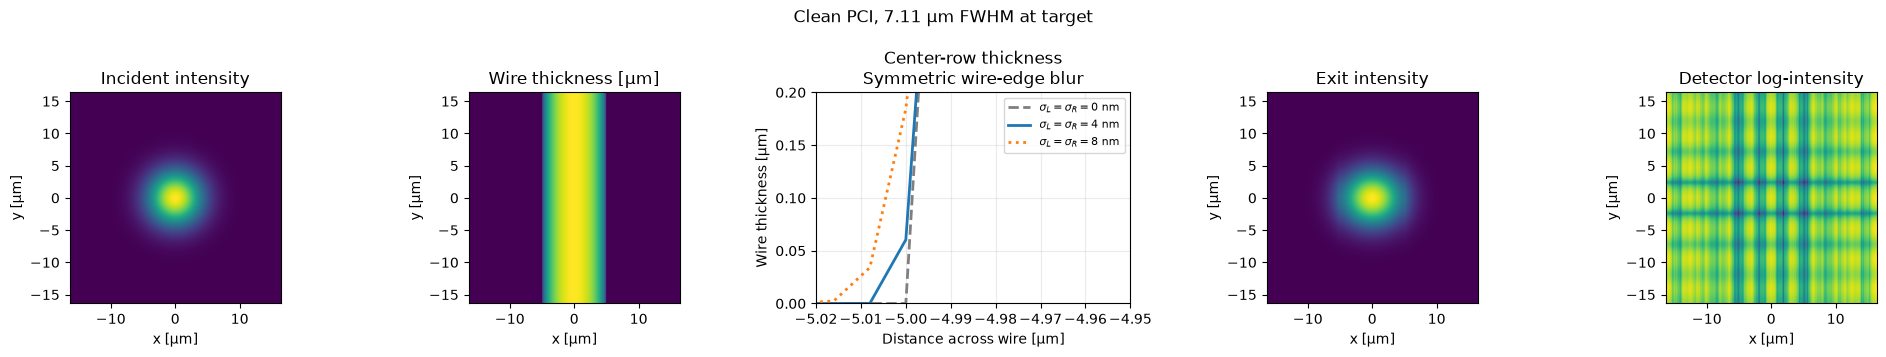

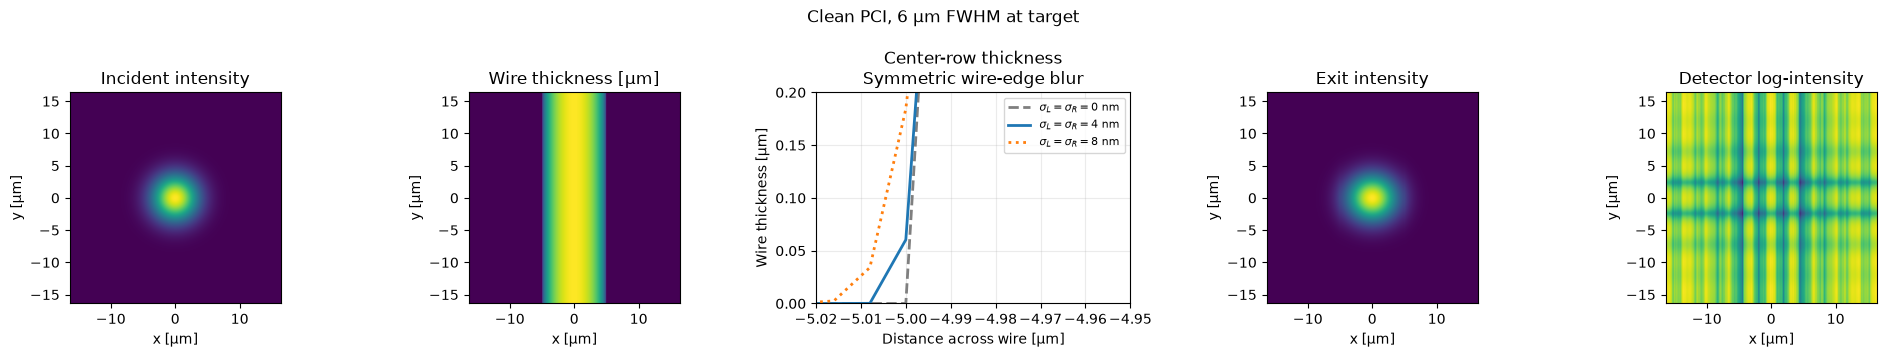

In [ ]:
CLEAN_PCI_DIR = OUTPUT_DIR / "clean_pci"
from scipy.ndimage import gaussian_filter1d

# Match notebook 01's centered chord on the shared 8 nm sample grid.
# Start every sigma case from the unblurred chord to avoid cumulative blur.
wire_radius_nm = 5.0 * PCI.um
wire_sample_offsets = np.arange(N_GRID) - N_GRID // 2
unblurred_thickness_profile_nm = 2.0 * np.sqrt(np.clip(
    (wire_radius_nm / PIXEL_SIZE)**2 - wire_sample_offsets**2, 0.0, None
)) * PIXEL_SIZE
thickness_sigma_cases = (
    (0.0, "tab:gray", "--"),
    (4.0, "tab:blue", "-"),
    (8.0, "tab:orange", ":"),
)
thickness_profiles_by_sigma_um = {}
for sigma_nm, _, _ in thickness_sigma_cases:
    profile_nm = unblurred_thickness_profile_nm.copy() if sigma_nm == 0 else (
        gaussian_filter1d(
            unblurred_thickness_profile_nm, sigma=sigma_nm / PIXEL_SIZE,
            mode="constant", cval=0.0, truncate=3.0,
        )
    )
    thickness_profiles_by_sigma_um[sigma_nm] = profile_nm.astype(np.float32) / PCI.um

clean_pci_field_cases = {
    "7p11um": {
        "fwhm_um": 7.11,
        "fields": PLOT_DATA_DIR / "clean_pci_fields.npz",
        "detector": CLEAN_PCI_DIR / "clean_pci_detector_intensity.tif",
        "figure": CLEAN_PCI_DIR / "clean_pci_field_overview.png",
    },
    "6um": {
        "fwhm_um": 6.0,
        "fields": PLOT_DATA_DIR / "clean_pci_fields_6um.npz",
        "detector": CLEAN_PCI_DIR / "clean_pci_detector_intensity_6um.tif",
        "figure": CLEAN_PCI_DIR / "clean_pci_field_overview_6um.png",
    },
}
for case in clean_pci_field_cases.values():
    with np.load(require(case["fields"])) as fields:
        detector_intensity = load_tiff(require(case["detector"]))
        extent_um = fields["extent_um"] # extent is the spatial extent of the field in micrometers, e.g., [x_min, x_max, y_min, y_max]
        thickness_um = fields["thickness_um"]
        fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
        axes[0].imshow(fields["incident_intensity"], extent=extent_um, origin="lower") 
        axes[0].set_title("Incident intensity")
        axes[1].imshow(thickness_um, extent=extent_um, origin="lower")
        axes[1].set_title("Wire thickness [µm]")
        for sigma_nm, color, linestyle in thickness_sigma_cases:
            thickness_profile_um = thickness_profiles_by_sigma_um[sigma_nm]
            axes[2].plot(
                SAMPLE_AXIS_UM, thickness_profile_um, color=color, lw=2,
                linestyle=linestyle, label=rf"$\sigma_L=\sigma_R={sigma_nm:g}$ nm",
            )
        axes[2].set(
            xlabel="Distance across wire [µm]", ylabel="Wire thickness [µm]",
            title="Center-row thickness\nSymmetric wire-edge blur",
            xlim=(-5.02, -4.95),
            ylim=(0, 0.2),
        )
        axes[2].set_ylim(bottom=0)
        axes[2].grid(alpha=0.25)
        axes[2].legend(loc="upper right", fontsize=8)
        axes[3].imshow(fields["exit_intensity"], extent=extent_um, origin="lower")
        axes[3].set_title("Exit intensity")
        axes[4].imshow(
            np.log10(detector_intensity + detector_intensity.max() * 1e-8),
            extent=extent_um, origin="lower",
        )
        axes[4].set_title("Detector log-intensity")
        for axis in (axes[0], axes[1], axes[3], axes[4]):
            axis.set_xlabel("x [µm]"); axis.set_ylabel("y [µm]")
        fig.suptitle(f"Clean PCI, {case['fwhm_um']:g} µm FWHM at target")
        fig.tight_layout()
        save_figure(fig, case["figure"])
        plt.show()


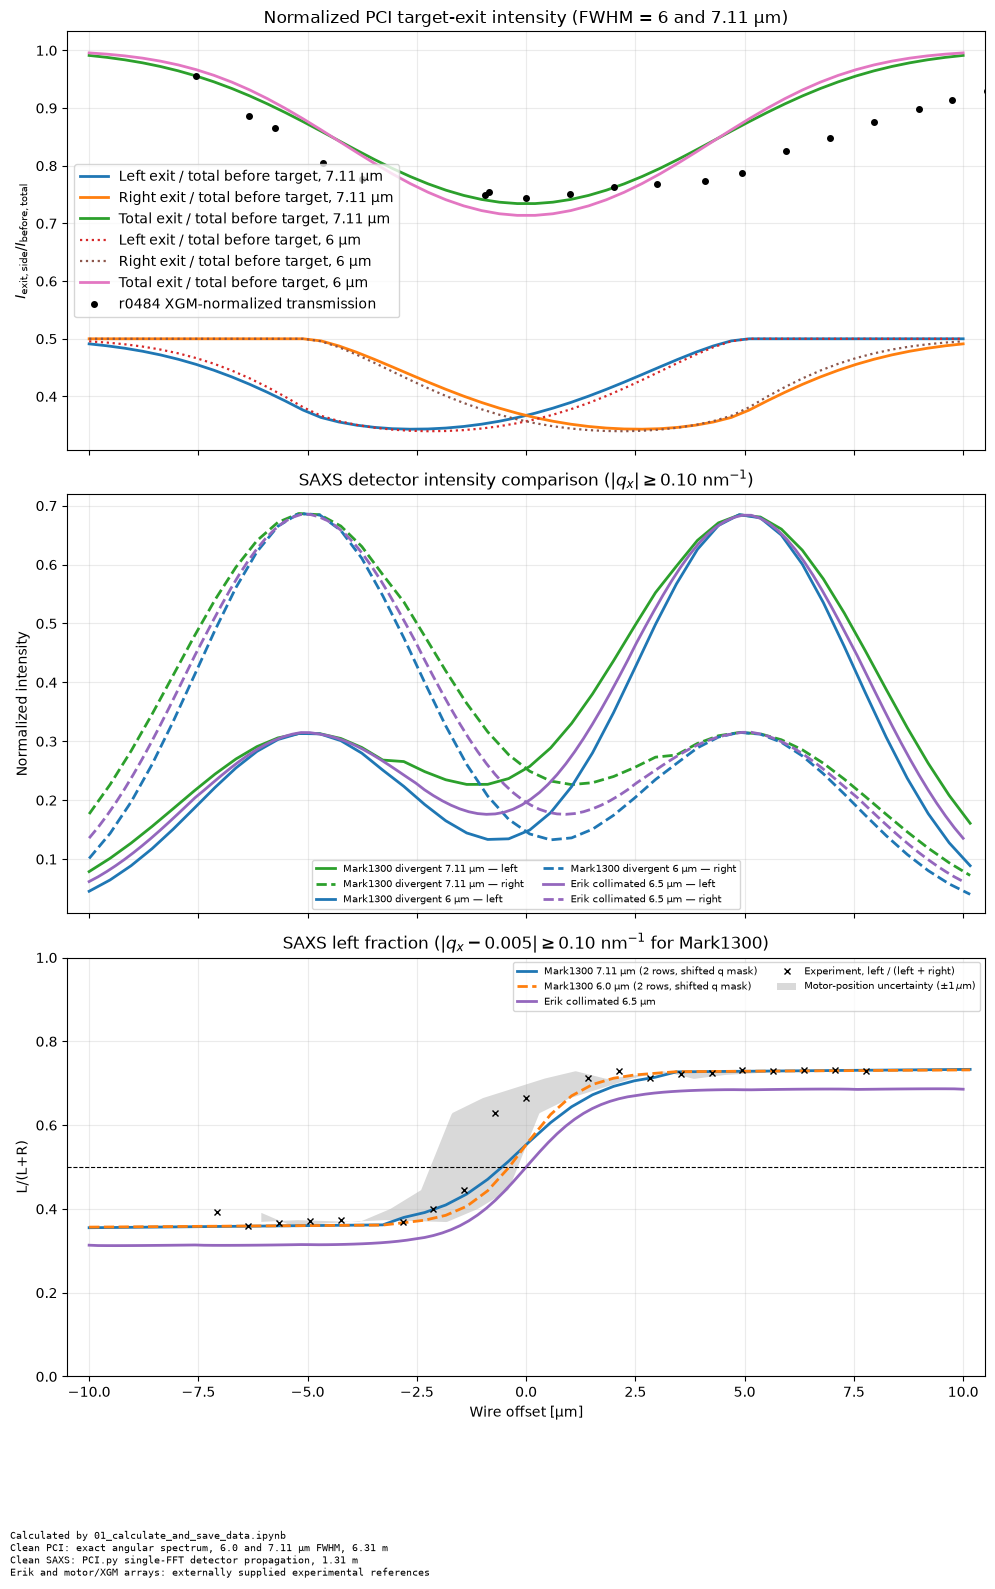

In [9]:
clean_pci = np.loadtxt(require(CLEAN_PCI_DIR / "pci_exit_left_right_vs_offset.dat"))
clean_pci_6 = np.loadtxt(require(CLEAN_PCI_DIR / "pci_exit_left_right_vs_offset_6um.dat"))
saxs_7 = np.loadtxt(require(SAXS_TABLE_DIR / "DivSAXS_asymmetry_Mark1300_7p11um.dat"))
saxs_6 = np.loadtxt(require(SAXS_TABLE_DIR / "DivSAXS_asymmetry_Mark1300_6um.dat"))
q_shifted_7 = np.loadtxt(require(CLEAN_PCI_DIR / "mark1300_7p11um_shifted_q_mask_left_fraction.dat"))
q_shifted_6 = np.loadtxt(require(CLEAN_PCI_DIR / "mark1300_6p0um_shifted_q_mask_left_fraction.dat"))
for label, shifted_data in (("7.11 um", q_shifted_7), ("6.0 um", q_shifted_6)):
    if shifted_data.ndim != 2 or shifted_data.shape[1] != 3 or not np.all(np.isfinite(shifted_data)):
        raise ValueError(f"Invalid {label} shifted-q table: expected three finite columns")
if q_shifted_6.shape == q_shifted_7.shape and np.array_equal(q_shifted_6, q_shifted_7):
    raise ValueError("The 6.0 um shifted-q table duplicates the 7.11 um table")
fig, axes = plt.subplots(3, 1, figsize=(10, 16), sharex=True)
axes[0].plot(clean_pci[:, 0], clean_pci[:, 1], color="tab:blue", lw=2,
             label="Left exit / total before target, 7.11 µm")
axes[0].plot(clean_pci[:, 0], clean_pci[:, 2], color="tab:orange", lw=2,
             label="Right exit / total before target, 7.11 µm")
axes[0].plot(clean_pci[:, 0], clean_pci[:, 3], color="tab:green", lw=2,
             label="Total exit / total before target, 7.11 µm")
axes[0].plot(clean_pci_6[:, 0], clean_pci_6[:, 1], color="tab:red", lw=1.6, ls=":",
             label="Left exit / total before target, 6 µm")
axes[0].plot(clean_pci_6[:, 0], clean_pci_6[:, 2], color="tab:brown", lw=1.6, ls=":",
             label="Right exit / total before target, 6 µm")
axes[0].plot(clean_pci_6[:, 0], clean_pci_6[:, 3], color="tab:pink", lw=2,
             label="Total exit / total before target, 6 µm")
axes[0].plot(transmission_position_um, transmission, "ko", ms=4,
             label="r0484 XGM-normalized transmission")
axes[0].set(
    ylabel=r"$I_{\mathrm{exit,side}}/I_{\mathrm{before,total}}$",
    title="Normalized PCI target-exit intensity (FWHM = 6 and 7.11 µm)",
    xlim=(-10.5, 10.5),
)
axes[0].legend()

saxs_7_offsets_um, saxs_7_left, saxs_7_right = saxs_7[:, 0] / 1e3, saxs_7[:, 1], saxs_7[:, 2]
saxs_7_scale = np.nanmax(saxs_7_left + saxs_7_right)
axes[1].plot(saxs_7_offsets_um, saxs_7_left / saxs_7_scale, "-", color="tab:green", lw=2,
             label="Mark1300 divergent 7.11 µm — left")
axes[1].plot(saxs_7_offsets_um, saxs_7_right / saxs_7_scale, "--", color="tab:green", lw=2,
             label="Mark1300 divergent 7.11 µm — right")
saxs_6_offsets_um, saxs_6_left, saxs_6_right = saxs_6[:, 0] / 1e3, saxs_6[:, 1], saxs_6[:, 2]
saxs_6_scale = np.nanmax(saxs_6_left + saxs_6_right)
axes[1].plot(saxs_6_offsets_um, saxs_6_left / saxs_6_scale, "-", color="tab:blue", lw=2,
             label="Mark1300 divergent 6 µm — left")
axes[1].plot(saxs_6_offsets_um, saxs_6_right / saxs_6_scale, "--", color="tab:blue", lw=2,
             label="Mark1300 divergent 6 µm — right")
erik_scale = np.nanmax(erik["total"])
axes[1].plot(erik["offsets_um"], erik["left"] / erik_scale, "-", color="tab:purple", lw=2,
             label="Erik collimated 6.5 µm — left")
axes[1].plot(erik["offsets_um"], erik["right"] / erik_scale, "--", color="tab:purple", lw=2,
             label="Erik collimated 6.5 µm — right")
axes[1].set(
    ylabel="Normalized intensity",
    title=r"SAXS detector intensity comparison ($|q_x| \geq 0.10$ nm$^{-1}$)",
)
axes[1].legend(fontsize=7, ncol=2)

axes[2].plot(q_shifted_7[:, 0], q_shifted_7[:, 1], "-", color="tab:blue", lw=2,
             label="Mark1300 7.11 µm (2 rows, shifted q mask)")
axes[2].plot(q_shifted_6[:, 0], q_shifted_6[:, 1], "--", color="tab:orange", lw=2,
             label="Mark1300 6.0 µm (2 rows, shifted q mask)")
# axes[2].plot(q_shifted_6[:, 0], q_shifted_6[:, 2], "--", color="tab:green", lw=2,
#              label="Mark1300 6.0 µm (10 rows, shifted q mask)")
axes[2].plot(erik["offsets_um"], erik["left_fraction"], "-", color="tab:purple", lw=2,
             label="Erik collimated 6.5 µm")
axes[2].plot(erik["motor_offsets_um"], erik["motor_left_fraction"], "kx", ms=5,
             label="Experiment, left / (left + right)")
motor_order = np.argsort(erik["motor_offsets_um"])
motor_x = erik["motor_offsets_um"][motor_order]
motor_y = erik["motor_left_fraction"][motor_order]
motor_band_x = np.linspace(motor_x.min() + 1, motor_x.max() - 1, 500)
motor_shift_plus = np.interp(motor_band_x - 1, motor_x, motor_y)
motor_shift_minus = np.interp(motor_band_x + 1, motor_x, motor_y)
axes[2].fill_between(
    motor_band_x,
    np.minimum(motor_shift_plus, motor_shift_minus),
    np.maximum(motor_shift_plus, motor_shift_minus),
    color="k", alpha=0.15, lw=0, zorder=0,
    label=r"Motor-position uncertainty ($\pm 1\,\mu$m)",
)

axes[2].axhline(0.5, color="k", lw=0.8, ls="--")
axes[2].set(
    xlabel="Wire offset [µm]", ylabel="L/(L+R)", ylim=(0, 1),
    title=r"SAXS left fraction ($|q_x - 0.005| \geq 0.10$ nm$^{-1}$ for Mark1300)", 
)
axes[2].legend(fontsize=7, ncol=2)
for axis in axes:
    axis.grid(alpha=0.25)
fig.text(
    0.01, 0.01,
    "Calculated by 01_calculate_and_save_data.ipynb\n"
    "Clean PCI: exact angular spectrum, 6.0 and 7.11 µm FWHM, 6.31 m\n"
    "Clean SAXS: PCI.py single-FFT detector propagation, 1.31 m\n"
    "Erik and motor/XGM arrays: externally supplied experimental references",
    ha="left", va="bottom", fontsize=7, family="monospace",
)
fig.tight_layout(rect=(0, 0.10, 1, 1))
save_figure(fig, CLEAN_PCI_DIR / "clean_pci_saxs_mark1300_left_right_vs_offset.png")
plt.show()


## 4. Realistic-profile figures


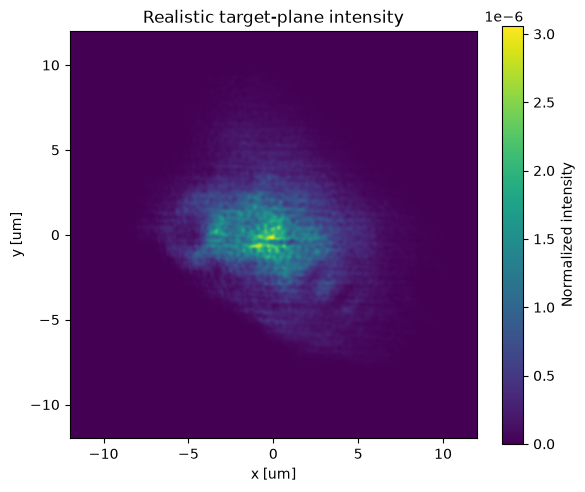

In [2]:
# Keep this section runnable independently after the global setup cell.
REALISTIC_DIR = OUTPUT_DIR / "realistic_profile"
REALISTIC_TABLE_DIR = REALISTIC_DIR / "tables"
REALISTIC_FIGURE_DIR = REALISTIC_DIR / "figures"
REALISTIC_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

incident = np.load(require(PLOT_DATA_DIR / "realistic_incident_intensity.npy"))
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(
    incident, origin="lower", extent=SAMPLE_EXTENT_UM, cmap="viridis", vmin=0, vmax=incident.max()
)
ax.set(
    xlabel="x [um]", ylabel="y [um]", title="Realistic target-plane intensity",
    xlim=(-12, 12), ylim=(-12, 12),
)
fig.colorbar(image, ax=ax, label="Normalized intensity")
fig.tight_layout()
save_figure(fig, REALISTIC_FIGURE_DIR / "00_realistic_incident_profile.png")
plt.show()
del incident


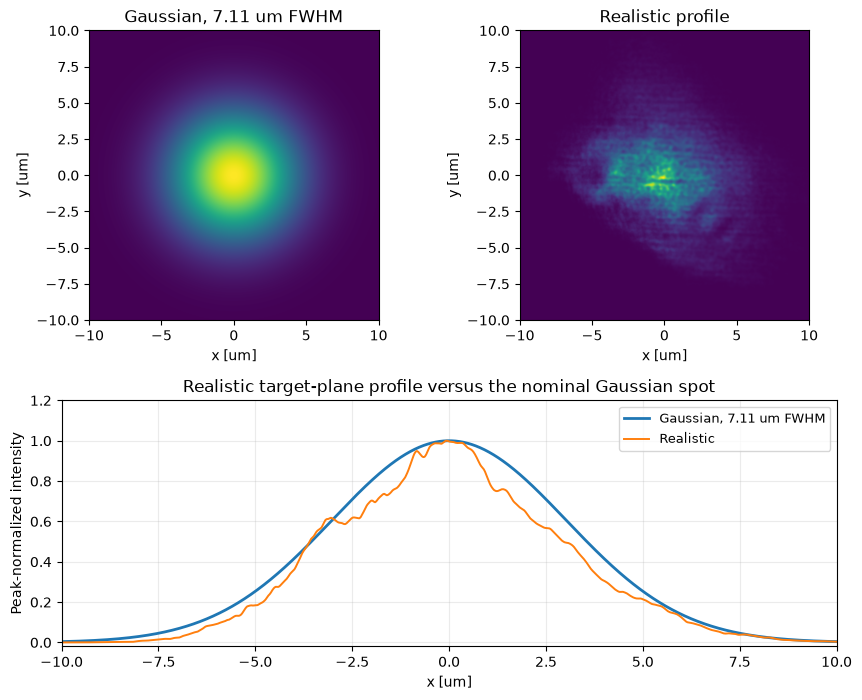

In [3]:
# Realistic target-plane profile against the nominal 7.11 um FWHM Gaussian spot.
REALISTIC_DIR = OUTPUT_DIR / "realistic_profile"
REALISTIC_FIGURE_DIR = REALISTIC_DIR / "figures"
REALISTIC_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
GAUSSIAN_FWHM_UM = 7.11                # Gaussian FWHM at the target used by the clean SAXS/PCI cases
PROFILE_VIEW_HALF_WIDTH_UM = 10.0      # display window shared by both maps and the lineout
FWHM_PER_SIGMA = 2 * np.sqrt(2 * np.log(2))

view_indices = np.flatnonzero(np.abs(SAMPLE_AXIS_UM) <= PROFILE_VIEW_HALF_WIDTH_UM)
view = slice(view_indices[0], view_indices[-1] + 1)
view_axis_um = SAMPLE_AXIS_UM[view]
view_extent_um = [view_axis_um[0], view_axis_um[-1]] * 2

incident = np.load(require(PLOT_DATA_DIR / "realistic_incident_intensity.npy"))
realistic_map = np.asarray(incident[view, view], dtype=np.float32)
del incident
realistic_map /= realistic_map.max()

# Ideal Gaussian sampled on the same grid, so both maps are directly comparable.
gaussian_1d = np.exp(
    -0.5 * (view_axis_um / (GAUSSIAN_FWHM_UM / FWHM_PER_SIGMA)) ** 2
).astype(np.float32)
gaussian_map = np.outer(gaussian_1d, gaussian_1d)

# The realistic profile is speckled, so both lineouts are y-projections of the same
# window instead of single rows; for a Gaussian that projection is the same Gaussian.
realistic_lineout = realistic_map.sum(axis=0, dtype=np.float64)
realistic_lineout /= realistic_lineout.max()
gaussian_lineout = gaussian_map.sum(axis=0, dtype=np.float64)
gaussian_lineout /= gaussian_lineout.max()

fig = plt.figure(figsize=(10, 8))
grid = fig.add_gridspec(2, 2, height_ratios=[1.0, 0.85], hspace=0.3, wspace=0.25)
for column, (profile_map, title) in enumerate((
    (gaussian_map, f"Gaussian, {GAUSSIAN_FWHM_UM:g} um FWHM"),
    (realistic_map, "Realistic profile"),
)):
    axis = fig.add_subplot(grid[0, column])
    axis.imshow(profile_map, origin="lower", extent=view_extent_um,
                cmap="viridis", vmin=0.0, vmax=1.0)
    axis.set(xlabel="x [um]", ylabel="y [um]", title=title, aspect="equal")

lineout_axis = fig.add_subplot(grid[1, :])
lineout_axis.plot(view_axis_um, gaussian_lineout, "-", lw=2, color="tab:blue",
                  label=f"Gaussian, {GAUSSIAN_FWHM_UM:g} um FWHM")
lineout_axis.plot(view_axis_um, realistic_lineout, "-", lw=1.4, color="tab:orange",
                  label="Realistic")
lineout_axis.set(
    xlabel="x [um]", ylabel="Peak-normalized intensity",
    xlim=(-PROFILE_VIEW_HALF_WIDTH_UM, PROFILE_VIEW_HALF_WIDTH_UM), ylim=(-0.02, 1.2),
    title="Realistic target-plane profile versus the nominal Gaussian spot",
)
lineout_axis.grid(alpha=0.25)
lineout_axis.legend(loc="upper right", fontsize=9)
save_figure(fig, REALISTIC_FIGURE_DIR / "01_realistic_vs_gaussian_profile.png")
plt.show()
del realistic_map, gaussian_map


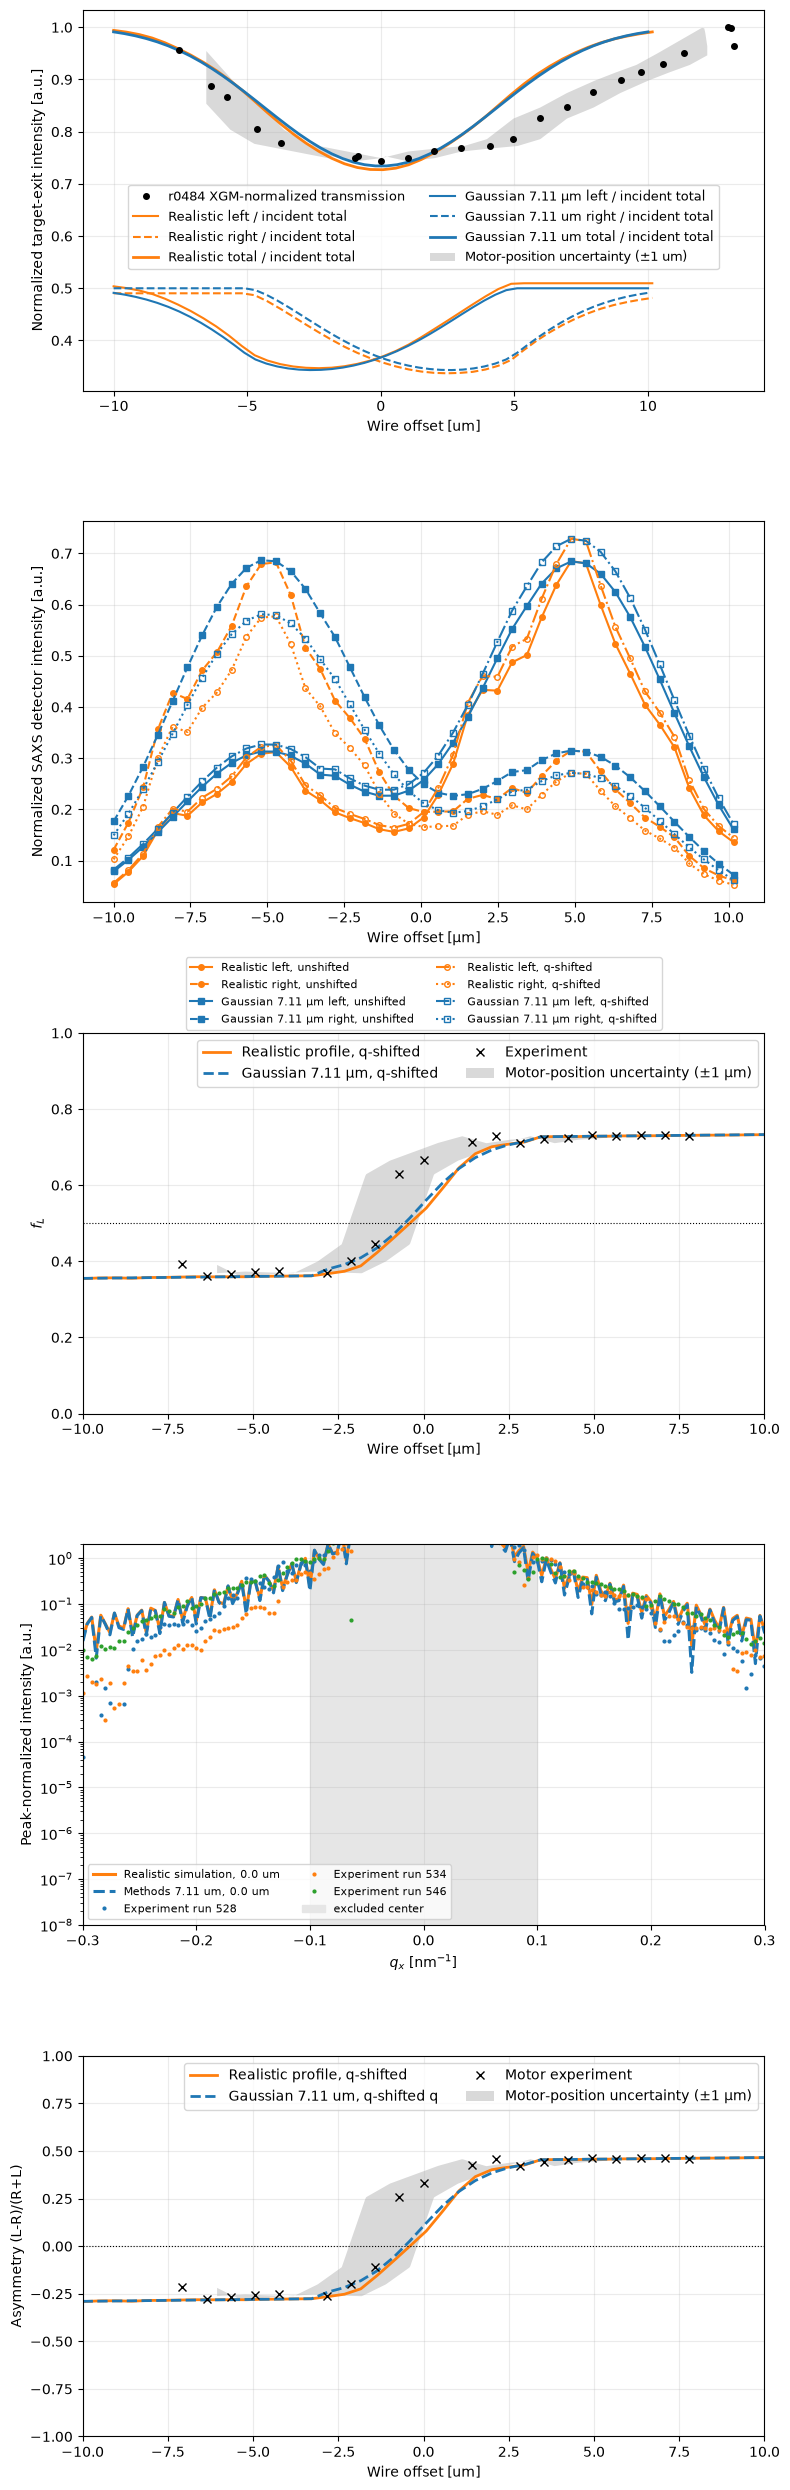

In [9]:
REALISTIC_DIR = OUTPUT_DIR / "realistic_profile"
REALISTIC_TABLE_DIR = REALISTIC_DIR / "tables"
REALISTIC_FIGURE_DIR = REALISTIC_DIR / "figures"
REALISTIC_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

EXPERIMENTAL_DIR = OUTPUT_DIR / "experimental_comparison"
EXPERIMENTAL_TABLE_DIR = EXPERIMENTAL_DIR / "tables"
EXPERIMENTAL_PCI_TIFF_DIR = EXPERIMENTAL_DIR / "pci_exit_tiffs"
EXPERIMENTAL_FIGURE_DIR = EXPERIMENTAL_DIR / "figures"

SAXS_OUTPUT_DIR = OUTPUT_DIR / "saxs"
SAXS_TABLE_DIR = SAXS_OUTPUT_DIR / "tables"
SAXS_FIGURE_DIR = SAXS_OUTPUT_DIR / "figures"
SAXS_TIFF_ROOT = SAXS_OUTPUT_DIR / "detector_tiffs" / f"Data_{PIXEL_SIZE:g}nm"

methods_profiles = np.load(require(PLOT_DATA_DIR / "methods_pointing_profiles.npz"))
sim_transmission = np.loadtxt(require(EXPERIMENTAL_TABLE_DIR / "analytic_exit_transmission.dat"))
realistic_pci = np.loadtxt(require(REALISTIC_TABLE_DIR / "realistic_profile_pci_exit_left_right.dat"))
# Gaussian columns are already normalized by the Gaussian incident total.
gaussian_pci = np.loadtxt(require(CLEAN_PCI_DIR / "pci_exit_left_right_vs_offset.dat"))
realistic_saxs = np.loadtxt(require(REALISTIC_TABLE_DIR / "realistic_profile_saxs_left_right.dat"))
realistic_bundle = np.load(require(PLOT_DATA_DIR / "realistic_saxs_lineouts.npz"))
realistic_offsets_um = realistic_pci[:, 0]
realistic_lineouts = realistic_bundle["lineouts"]
realistic_q_axis = realistic_bundle["q_axis"]
realistic_experimental = {run: load_realistic_experimental_profile(run) for run in EXPERIMENTAL_RUNS}

gaussian = np.loadtxt(require(SAXS_TABLE_DIR / "DivSAXS_asymmetry_Mark1300_7p11um.dat"))
q_shifted_gaussian = np.loadtxt(
    require(CLEAN_PCI_DIR / "mark1300_7p11um_shifted_q_mask_left_fraction.dat")
)
gaussian_offsets_um = gaussian[:, 0] / 1e3
gaussian_left, gaussian_right = gaussian[:, 1], gaussian[:, 2]
gaussian_total = gaussian_left + gaussian_right
lingen = np.loadtxt(require(LINGEN_REFERENCE_PATH))
methods_zero_index = int(np.argmin(np.abs(methods_profiles["offsets_um"])))
methods_profile_q = methods_profiles["q"]
methods_profile = methods_profiles["lineouts"][methods_zero_index].astype(float)

real_pci_left, real_pci_right = realistic_pci[:, 1], realistic_pci[:, 2]
real_pci_total = realistic_pci[:, 3]
incident_total = np.nanmedian(real_pci_total / realistic_pci[:, 5])
real_saxs_left, real_saxs_right = realistic_saxs[:, 1], realistic_saxs[:, 2]
real_saxs_total = real_saxs_left + real_saxs_right
shifted_q_axis = (
    np.arange(realistic_lineouts.shape[1]) - realistic_lineouts.shape[1] // 2
) * Q_STEP
shifted_left_edge = Q_MASK_SHIFT_NM_INV - Q_MIN
shifted_right_edge = Q_MASK_SHIFT_NM_INV + Q_MIN
shifted_left_weights = np.clip(
    (shifted_left_edge - shifted_q_axis) / Q_STEP + 0.5, 0.0, 1.0
)
shifted_right_weights = np.clip(
    (shifted_q_axis - shifted_right_edge) / Q_STEP + 0.5, 0.0, 1.0
)
realistic_shifted_left = realistic_lineouts @ shifted_left_weights
realistic_shifted_right = realistic_lineouts @ shifted_right_weights
realistic_shifted_fraction = realistic_shifted_left / (
    realistic_shifted_left + realistic_shifted_right
)

# Recover raw Gaussian two-row lineouts; the saved pointing profiles are
# normalized separately at each offset and cannot preserve scan intensities.
gaussian_shifted_left, gaussian_shifted_right = [], []
for offset_um in gaussian_offsets_um:
    gaussian_intensity = load_tiff(
        SAXS_TIFF_ROOT / "mark1300_7p11um" / f"SAXS_Offset{offset_um:.2f}um.tif"
    )
    gaussian_center = gaussian_intensity.shape[0] // 2
    gaussian_lineout = gaussian_intensity[gaussian_center - 1:gaussian_center + 1].mean(axis=0)
    gaussian_shifted_left.append(gaussian_lineout @ shifted_left_weights)
    gaussian_shifted_right.append(gaussian_lineout @ shifted_right_weights)
    del gaussian_intensity
gaussian_shifted_left = np.asarray(gaussian_shifted_left)
gaussian_shifted_right = np.asarray(gaussian_shifted_right)

fig, axes = plt.subplots(5, 1, figsize=(8, 25))
axes[0].plot(transmission_position_um, transmission, "ko", ms=4, zorder=5,
             label="r0484 XGM-normalized transmission")
axes[0].plot(realistic_offsets_um, real_pci_left / incident_total, "-",
             color="tab:orange", label="Realistic left / incident total")
axes[0].plot(realistic_offsets_um, real_pci_right / incident_total, "--",
             color="tab:orange", label="Realistic right / incident total")
axes[0].plot(realistic_offsets_um, real_pci_total / incident_total, "-", lw=2,
             color="tab:orange", label="Realistic total / incident total")
axes[0].plot(gaussian_pci[:, 0], gaussian_pci[:, 1], "-",
             color="tab:blue", label="Gaussian 7.11 µm left / incident total")
axes[0].plot(gaussian_pci[:, 0], gaussian_pci[:, 2], "--",
             color="tab:blue", label="Gaussian 7.11 um right / incident total")
axes[0].plot(gaussian_pci[:, 0], gaussian_pci[:, 3], "-", lw=2,
             color="tab:blue", label="Gaussian 7.11 um total / incident total")

transmission_order = np.argsort(transmission_position_um) # Sort transmission data by wire offset ascending
transmission_x = transmission_position_um[transmission_order]
transmission_y = transmission[transmission_order]
transmission_band_x = np.linspace(
    transmission_x.min() + MOTOR_POSITION_UNCERTAINTY_UM,
    transmission_x.max() - MOTOR_POSITION_UNCERTAINTY_UM,
    500,
)
transmission_shift_plus = np.interp(
    transmission_band_x - MOTOR_POSITION_UNCERTAINTY_UM, transmission_x, transmission_y
)
transmission_shift_minus = np.interp(
    transmission_band_x + MOTOR_POSITION_UNCERTAINTY_UM, transmission_x, transmission_y
)
axes[0].fill_between(
    transmission_band_x,
    np.minimum(transmission_shift_plus, transmission_shift_minus),
    np.maximum(transmission_shift_plus, transmission_shift_minus),
    color="k", alpha=0.15, lw=0, zorder=0,
    label=rf"Motor-position uncertainty ($\pm${MOTOR_POSITION_UNCERTAINTY_UM:g} um)",
)
axes[0].set(
    xlabel="Wire offset [um]", ylabel="Normalized target-exit intensity [a.u.]",
    # title="PCI target-exit signal: realistic and Gaussian 7.11 um",
)
axes[0].legend(ncol=2, fontsize=9, loc="center", bbox_to_anchor=(0.5, 0.43))

real_scale, gaussian_scale = real_saxs_total.max(), gaussian_total.max()
# Preserve each mask's normalization by its maximum total over the scan.
realistic_shifted_scale = (realistic_shifted_left + realistic_shifted_right).max()
gaussian_shifted_scale = (gaussian_shifted_left + gaussian_shifted_right).max()
axes[1].plot(realistic_offsets_um, real_saxs_left / real_scale, "o-", ms=4,
             color="tab:orange", label="Realistic left, unshifted")
axes[1].plot(realistic_offsets_um, real_saxs_right / real_scale, "o--", ms=4,
             color="tab:orange", label="Realistic right, unshifted")
axes[1].plot(gaussian_offsets_um, gaussian_left / gaussian_scale, "s-", ms=4,
             color="tab:blue", label="Gaussian 7.11 µm left, unshifted")
axes[1].plot(gaussian_offsets_um, gaussian_right / gaussian_scale, "s--", ms=4,
             color="tab:blue", label="Gaussian 7.11 µm right, unshifted")
axes[1].plot(realistic_offsets_um, realistic_shifted_left / realistic_shifted_scale,
             "o-.", ms=4, mfc="none", color="tab:orange", label="Realistic left, q-shifted")
axes[1].plot(realistic_offsets_um, realistic_shifted_right / realistic_shifted_scale,
             "o:", ms=4, mfc="none", color="tab:orange", label="Realistic right, q-shifted")
axes[1].plot(gaussian_offsets_um, gaussian_shifted_left / gaussian_shifted_scale,
             "s-.", ms=4, mfc="none", color="tab:blue", label="Gaussian 7.11 µm left, q-shifted")
axes[1].plot(gaussian_offsets_um, gaussian_shifted_right / gaussian_shifted_scale,
             "s:", ms=4, mfc="none", color="tab:blue", label="Gaussian 7.11 µm right, q-shifted")
axes[1].set(
    xlabel="Wire offset [µm]", ylabel="Normalized SAXS detector intensity [a.u.]",
    # title=("Simulated Mark1300 SAXS left/right: unshifted and q-shifted\n"
    #        rf"($|q_x-q_{{\mathrm{{shift}}}}| \geq {Q_MIN:g}$ nm$^{{-1}}$; "
    #        rf"$q_{{\mathrm{{shift}}}}=0,\ +{Q_MASK_SHIFT_NM_INV:g}$ nm$^{{-1}}$)"),
)
axes[1].legend(ncol=2, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.35))
axes[2].plot(realistic_offsets_um, realistic_shifted_fraction, "-", lw=2,
             color="tab:orange", label="Realistic profile, q-shifted")
axes[2].plot(q_shifted_gaussian[:, 0], q_shifted_gaussian[:, 1], "--", lw=2,
             color="tab:blue", label="Gaussian 7.11 µm, q-shifted")
# axes[2].plot(erik["offsets_um"], erik["left_fraction"], "-", lw=2,
#              color="tab:green", label="Erik collimated simulation")
# axes[2].plot(lingen[:, 0] / 1e3, lingen[:, 1] / (lingen[:, 1] + lingen[:, 2]),
#              "d-", ms=4, color="tab:purple", label="Lingen reference (6 µm)")
axes[2].plot(
    erik["motor_offsets_um"], erik["motor_left_fraction"], "kx", ms=6,
    label="Experiment", zorder=5,
)
motor_order = np.argsort(erik["motor_offsets_um"])
motor_x = erik["motor_offsets_um"][motor_order]
motor_y = erik["motor_left_fraction"][motor_order]
motor_band_x = np.linspace(
    motor_x.min() + MOTOR_POSITION_UNCERTAINTY_UM,
    motor_x.max() - MOTOR_POSITION_UNCERTAINTY_UM,
    500,
)
motor_shift_plus = np.interp(
    motor_band_x - MOTOR_POSITION_UNCERTAINTY_UM, motor_x, motor_y
)
motor_shift_minus = np.interp(
    motor_band_x + MOTOR_POSITION_UNCERTAINTY_UM, motor_x, motor_y
)
axes[2].fill_between(           # fill_between(x, y1, y2) to show motor position uncertainty, y1=lower bound, y2=upper bound
    motor_band_x,
    np.minimum(motor_shift_plus, motor_shift_minus),
    np.maximum(motor_shift_plus, motor_shift_minus),
    color="k", alpha=0.15, lw=0, zorder=0,
    label=rf"Motor-position uncertainty ($\pm${MOTOR_POSITION_UNCERTAINTY_UM:g} µm)",
)
axes[2].axhline(0.5, color="k", lw=0.8, ls=":")
axes[2].set(
    xlabel="Wire offset [µm]", ylabel=r"$f_L$", xlim=(-10, 10), ylim=(0, 1),
    # title=("SAXS left ratio versus motor experiment "
    #        rf"($|q_x-{Q_MASK_SHIFT_NM_INV:g}| \geq {Q_MIN:g}$ nm$^{{-1}}$)"),
)
axes[2].legend(ncol=2)

profile_index = int(np.argmin(np.abs(realistic_offsets_um)))
realistic_interp = interpolate.interp1d(
    realistic_q_axis, realistic_lineouts[profile_index], kind="linear", fill_value="extrapolate"
)(methods_profile_q)
profile_mask = (np.abs(methods_profile_q) >= Q_MIN) & (np.abs(methods_profile_q) <= Q_COMPARE_MAX)
realistic_interp /= realistic_interp[profile_mask].max()
methods_profile /= methods_profile[profile_mask].max()
axes[3].semilogy(methods_profile_q, np.maximum(realistic_interp, 1e-10), "-", lw=2.2,
                 color="tab:orange", label="Realistic simulation, 0.0 um")
axes[3].semilogy(methods_profile_q, np.maximum(methods_profile, 1e-10), "--", lw=2.2,
                 color="tab:blue", label="Methods 7.11 um, 0.0 um")
for run, profile in realistic_experimental.items():
    axes[3].semilogy(profile["q"], np.maximum(profile["normalized"], 1e-10), ".", ms=4,
                     label=f"Experiment run {run}")
axes[3].axvspan(-Q_MIN, Q_MIN, color="0.9", label="excluded center")
axes[3].set(
    xlabel=r"$q_x$ [nm$^{-1}$]", ylabel="Peak-normalized intensity [a.u.]",
    xlim=(-Q_COMPARE_MAX, Q_COMPARE_MAX), ylim=(1e-8, 2),
)
axes[3].legend(fontsize=8, ncol=2)

# Convert the same shifted-mask left fractions to signed asymmetry:
# (L-R)/(R+L) = 2*L/(L+R) - 1, also valid for the saved motor data.
axes[4].plot(realistic_offsets_um, 2 * realistic_shifted_fraction - 1, "-", lw=2,
             color="tab:orange", label="Realistic profile, q-shifted")
axes[4].plot(q_shifted_gaussian[:, 0], 2 * q_shifted_gaussian[:, 1] - 1, "--", lw=2,
             color="tab:blue", label="Gaussian 7.11 um, q-shifted q")
# axes[4].plot(erik["offsets_um"], 2 * erik["left_fraction"] - 1, "-", lw=2,
#              color="tab:green", label="Erik collimated simulation")
axes[4].plot(
    erik["motor_offsets_um"], 2 * erik["motor_left_fraction"] - 1, "kx", ms=6,
    label="Motor experiment", zorder=5,
)
motor_asymmetry_shift_plus = 2 * motor_shift_plus - 1
motor_asymmetry_shift_minus = 2 * motor_shift_minus - 1
axes[4].fill_between(
    motor_band_x,
    np.minimum(motor_asymmetry_shift_plus, motor_asymmetry_shift_minus),
    np.maximum(motor_asymmetry_shift_plus, motor_asymmetry_shift_minus),
    color="k", alpha=0.15, lw=0, zorder=0,
    label=rf"Motor-position uncertainty ($\pm${MOTOR_POSITION_UNCERTAINTY_UM:g} µm)",
)
axes[4].axhline(0.0, color="k", lw=0.8, ls=":")
axes[4].set(
    xlabel="Wire offset [um]", ylabel="Asymmetry (L-R)/(R+L)",
    xlim=(-10, 10), ylim=(-1, 1),
    # title=("SAXS asymmetry versus motor experiment "
    #        rf"($|q_x-{Q_MASK_SHIFT_NM_INV:g}| \geq {Q_MIN:g}$ nm$^{{-1}}$)"),
)
axes[4].legend(ncol=2)

for axis in axes:
    axis.grid(alpha=0.25)
fig.tight_layout()
save_figure(fig, REALISTIC_FIGURE_DIR / "02_realistic_pci_saxs_left_right.png")
plt.show()


## 5. Gaussian experimental-comparison figures


In [5]:
EXPERIMENTAL_DIR = OUTPUT_DIR / "experimental_comparison"
EXPERIMENTAL_TABLE_DIR = EXPERIMENTAL_DIR / "tables"
EXPERIMENTAL_PCI_TIFF_DIR = EXPERIMENTAL_DIR / "pci_exit_tiffs"
EXPERIMENTAL_FIGURE_DIR = EXPERIMENTAL_DIR / "figures"
EXPERIMENTAL_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Physical PCI and SAXS comparison figures begin in the next cell.


In [14]:
# Read the exact 0.48 um Clean SAXS grid used by notebook 01.
comparison_offsets_um = np.loadtxt(
    require(SAXS_TABLE_DIR / "DivSAXS_asymmetry_Mark1300_7p11um.dat"),
)[:, 0] / 1e3
reference_pci = load_tiff(
    EXPERIMENTAL_PCI_TIFF_DIR / f"analytic_pci_exit_offset_{offset_tag(comparison_offsets_um[0])}um.tif"
)
pci_vmax = float(np.nanmax(reference_pci))
del reference_pci
for offset_um in comparison_offsets_um:
    tag = offset_tag(offset_um)
    pci_image = load_tiff(EXPERIMENTAL_PCI_TIFF_DIR / f"analytic_pci_exit_offset_{tag}um.tif")
    saxs_file_offset_um = -0.0 if np.isclose(offset_um, 0.0) else offset_um
    saxs_image = load_tiff(
        SAXS_TIFF_ROOT / "mark1300_7p11um" / f"SAXS_Offset{saxs_file_offset_um:.2f}um.tif"
    )
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    im0 = axes[0].imshow(
        pci_image, origin="lower", extent=SAMPLE_EXTENT_UM, cmap="inferno",
        vmin=0, vmax=pci_vmax, aspect="equal",
    )
    axes[0].set(
        xlabel="x (um)", ylabel="y (um)",
        title=rf"PCI exit: $|E_{{\rm out}}|^2$, wire offset {offset_um:+.1f} um",
    )
    fig.colorbar(im0, ax=axes[0], label="Intensity (a.u.)")
    im1 = axes[1].imshow(
        saxs_image, origin="lower", extent=Q_EXTENT, cmap="inferno",
        norm=LogNorm(vmin=1e-11, vmax=5e-8), aspect="auto",
    )
    axes[1].set(
        xlabel=r"$q_x$ (1/nm)", ylabel=r"$q_y$ (1/nm)",
        title=f"SAXS after {Z_SAXS_DETECTOR / PCI.m:.2f} m, wire offset {offset_um:+.1f} um",
        xlim=(-0.4, 0.4), ylim=(-0.005, 0.005),
    )
    fig.colorbar(im1, ax=axes[1], label="Intensity (a.u.)")
    fig.tight_layout()
    save_figure(
        fig, EXPERIMENTAL_FIGURE_DIR / f"01_exit_pci_and_saxs_offset_{tag}um.png", dpi=180
    )
    plt.close(fig)
    del pci_image, saxs_image
print(f"Experimental comparison gallery: {len(comparison_offsets_um)} figures")


Experimental comparison gallery: 43 figures


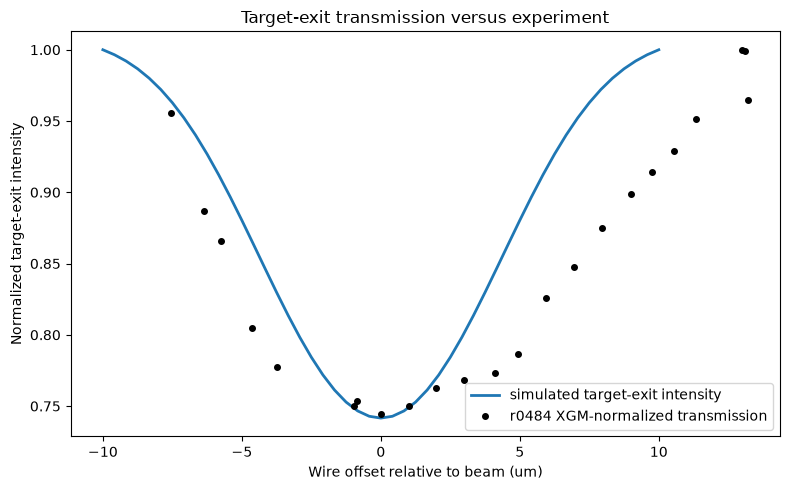

In [15]:
sim_transmission = np.loadtxt(require(EXPERIMENTAL_TABLE_DIR / "analytic_exit_transmission.dat"))
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sim_transmission[:, 0], sim_transmission[:, 1], "-", lw=2,
        label="simulated target-exit intensity")
ax.plot(transmission_position_um, transmission, "ko", ms=4,
        label="r0484 XGM-normalized transmission")
ax.set(
    xlabel="Wire offset relative to beam (um)",
    ylabel="Normalized target-exit intensity",
    title="Target-exit transmission versus experiment",
)
ax.legend(); fig.tight_layout()
save_figure(fig, EXPERIMENTAL_FIGURE_DIR / "04_exit_transmission.png", dpi=180)
plt.show()


Available arrays: ['incident_intensity', 'thickness_um', 'exit_intensity', 'extent_um', 'fwhm_um']
Sample values:
 [[3867.70846943 3867.76000506 3867.77680661 3867.76000506 3867.70846943]
 [3867.7656622  3867.81719859 3867.83400039 3867.81719859 3867.7656622 ]
 [3867.78472664 3867.83626329 3867.85306518 3867.83626329 3867.78472664]
 [3867.7656622  3867.81719859 3867.83400039 3867.81719859 3867.7656622 ]
 [3867.70846943 3867.76000506 3867.77680661 3867.76000506 3867.70846943]]


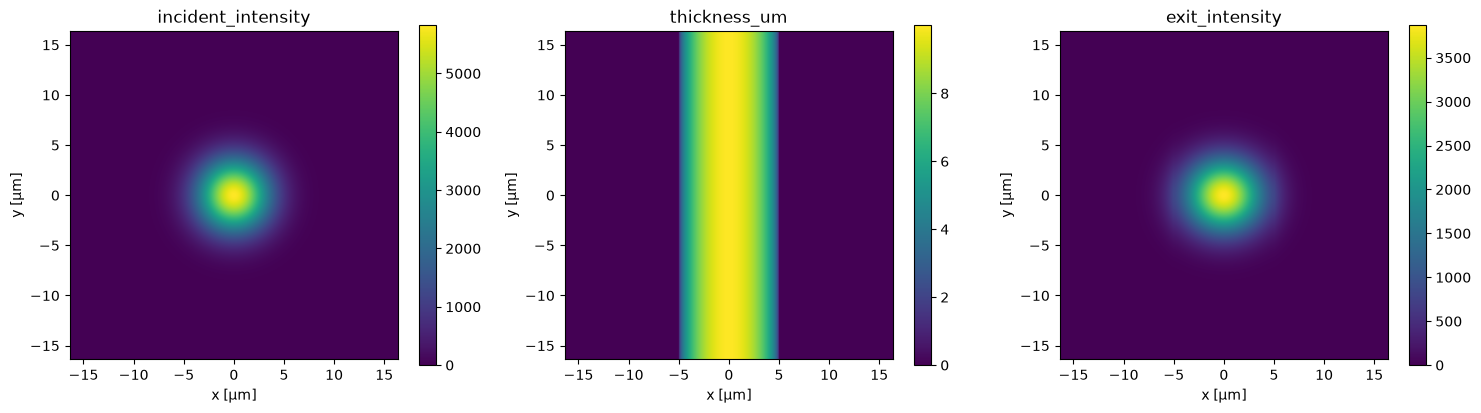

In [2]:
import numpy as np
import matplotlib.pyplot as plt

path = (
    "outputs/sigmaL_4nm_sigmaR_4nm/"
    "combined_plot_data/clean_pci_fields_6um.npz"
)

with np.load(path) as data:
    print("Available arrays:", data.files)
    print("Sample values:\n", data["exit_intensity"][2046:2051, 2046:2051])

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, key in zip(
        axes, ["incident_intensity", "thickness_um", "exit_intensity"]
    ):
        im = ax.imshow(
            data[key], origin="lower", extent=data["extent_um"]
        )
        ax.set(title=key, xlabel="x [µm]", ylabel="y [µm]")
        fig.colorbar(im, ax=ax)

    plt.tight_layout()
    plt.show()